In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.ensemble import IsolationForest
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
np.random.seed(42)

In [4]:
# Generate 500 normal records

normal = pd.DataFrame({
    'duration': np.random.normal(5, 1.5, 500),
    'bytes_sent': np.random.normal(500, 100, 500),
    'connections': np.random.normal(10, 3, 500),
    'label': 0
})

In [5]:
# Generate 25 attack records
attack = pd.DataFrame({
    'duration': np.random.normal(30, 5, 25),
    'bytes_sent': np.random.normal(5000, 800, 25),
    'connections': np.random.normal(120, 20, 25),
    'label': 1
})

In [6]:
# Combine the datasets
data = pd.concat(
    [normal, attack],
    ignore_index=True
)

print(data.head())

print("\nClass distribution:")
print(data['label'].value_counts())


   duration  bytes_sent  connections  label
0  5.745071  592.617755    14.198066      0
1  4.792604  690.941664    12.773901      0
2  5.971533  360.143243    10.178891      0
3  7.284545  556.296924     8.059190      0
4  4.648770  434.935743    12.094670      0

Class distribution:
label
0    500
1     25
Name: count, dtype: int64


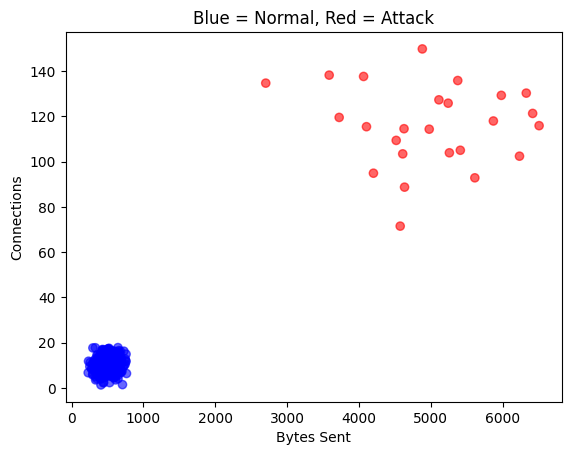

In [7]:
# Visualize actual records
colors = data['label'].map({
    0: 'blue',
    1: 'red'
})

plt.scatter(
    data['bytes_sent'],
    data['connections'],
    c=colors,
    alpha=0.6
)

plt.xlabel('Bytes Sent')
plt.ylabel('Connections')
plt.title('Blue = Normal, Red = Attack')
plt.show()

In [8]:
# Prepare training and testing data
X = data[
    ['duration', 'bytes_sent', 'connections']
]

y = data['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [9]:
# Decision Tree classifier
clf = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

clf.fit(X_train, y_train)

pred = clf.predict(X_test)

print("\nDecision Tree Confusion Matrix:")
print(confusion_matrix(y_test, pred))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, pred))



Decision Tree Confusion Matrix:
[[150   0]
 [  0   8]]

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       150
           1       1.00      1.00      1.00         8

    accuracy                           1.00       158
   macro avg       1.00      1.00      1.00       158
weighted avg       1.00      1.00      1.00       158



In [10]:
# Isolation Forest anomaly detection
iso = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

In [11]:
# Train without using the actual labels
iso.fit(X)

IsolationForest(contamination=0.05, random_state=42)

In [12]:
# Isolation Forest: 1 = normal, -1 = anomaly
data['pred'] = iso.predict(X)

In [13]:
# Convert to 0 = normal, 1 = anomaly
data['pred'] = data['pred'].map({
    1: 0,
    -1: 1
})


print("\nIsolation Forest Confusion Matrix:")
print(confusion_matrix(data['label'], data['pred']))

print("\nIsolation Forest Classification Report:")
print(classification_report(data['label'], data['pred']))


Isolation Forest Confusion Matrix:
[[498   2]
 [  0  25]]

Isolation Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       500
           1       0.93      1.00      0.96        25

    accuracy                           1.00       525
   macro avg       0.96      1.00      0.98       525
weighted avg       1.00      1.00      1.00       525



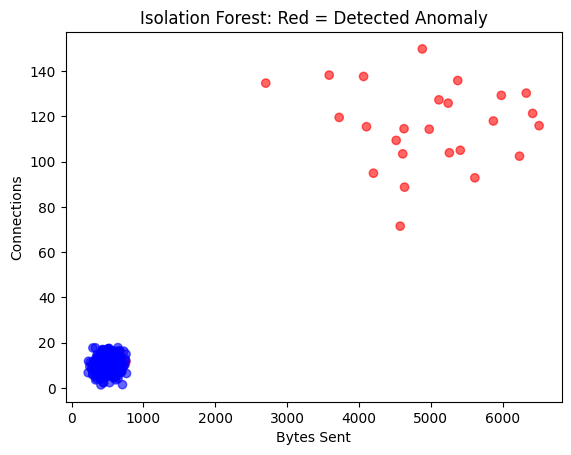

In [14]:
# Visualize detected anomalies
colors = data['pred'].map({
    0: 'blue',
    1: 'red'
})

plt.scatter(
    data['bytes_sent'],
    data['connections'],
    c=colors,
    alpha=0.6
)

plt.xlabel('Bytes Sent')
plt.ylabel('Connections')
plt.title('Isolation Forest: Red = Detected Anomaly')
plt.show()